In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv(
    "../data/raw/train.txt",
    sep=";",
    header=None,
    names=["text", "emotion"]
)

df.head()

,text,emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [3]:
print("Shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nEmotion counts:")
print(df["emotion"].value_counts())

Shape: (16000, 2)

Data types:
text       str
emotion    str
dtype: object

Missing values:
text       0
emotion    0
dtype: int64

Duplicate rows:
1

Emotion counts:
emotion
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64


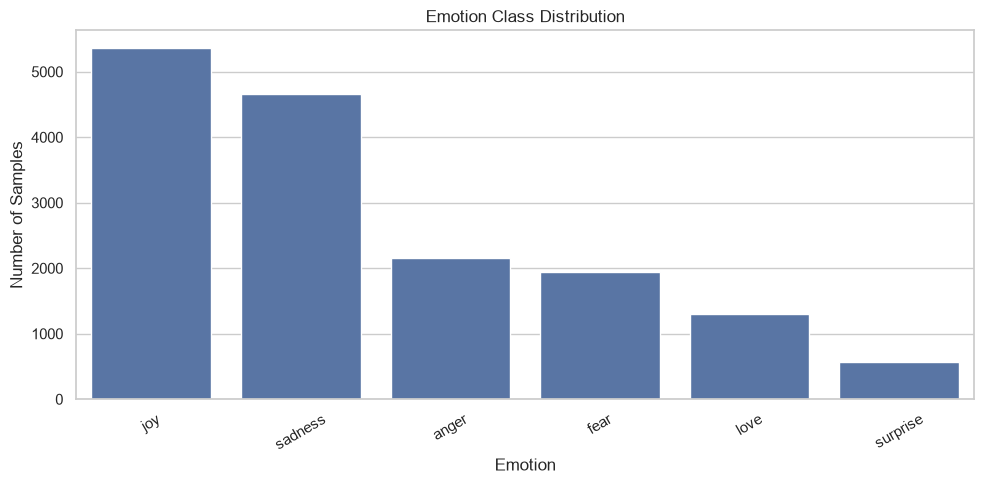

In [4]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="emotion",
    order=df["emotion"].value_counts().index
)

plt.title("Emotion Class Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

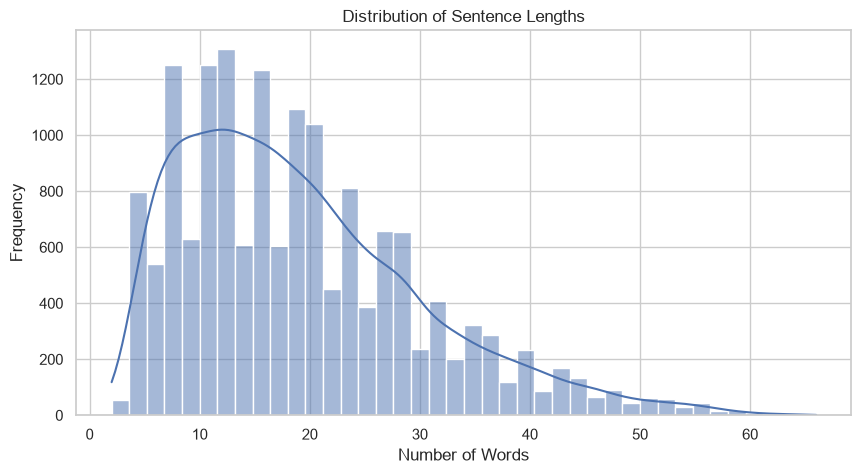

In [5]:
df["word_count"] = df["text"].apply(
    lambda x: len(str(x).split())
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=40,
    kde=True
)

plt.title("Distribution of Sentence Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [6]:
print("Dataset shape:", df.shape)

print("\nEmotion distribution:")
print(df["emotion"].value_counts())

print("\nEmotion percentages:")
print(df["emotion"].value_counts(normalize=True) * 100)

print("\nDuplicates:", df.duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum())

print("\nText length statistics:")
print(df["word_count"].describe())

Dataset shape: (16000, 3)

Emotion distribution:
emotion
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64

Emotion percentages:
emotion
joy         33.51250
sadness     29.16250
anger       13.49375
fear        12.10625
love         8.15000
surprise     3.57500
Name: proportion, dtype: float64

Duplicates: 1

Missing values:
text          0
emotion       0
word_count    0
dtype: int64

Text length statistics:
count    16000.000000
mean        19.166313
std         10.986905
min          2.000000
25%         11.000000
50%         17.000000
75%         25.000000
max         66.000000
Name: word_count, dtype: float64


In [7]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df[df.duplicated(keep=False)])

print("\nUnique emotion labels:")
print(df["emotion"].unique())

Missing values:
text          0
emotion       0
word_count    0
dtype: int64

Duplicate records:
                                                    text emotion  word_count
4975   i feel more adventurous willing to take risks ...     joy          12
13846  i feel more adventurous willing to take risks ...     joy          12

Unique emotion labels:
<ArrowStringArray>
['sadness', 'anger', 'love', 'surprise', 'fear', 'joy']
Length: 6, dtype: str


In [8]:
import re

df["text_original"] = df["text"].copy()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df["text_clean"] = df["text_original"].apply(clean_text)

df[["text_original", "text_clean"]].head(10)

,text_original,text_clean
0,i didnt feel humiliated,i didnt feel humiliated
1,i can go from feeling so hopeless to so damned...,i can go from feeling so hopeless to so damned...
2,im grabbing a minute to post i feel greedy wrong,im grabbing a minute to post i feel greedy wrong
3,i am ever feeling nostalgic about the fireplac...,i am ever feeling nostalgic about the fireplac...
4,i am feeling grouchy,i am feeling grouchy
5,ive been feeling a little burdened lately wasn...,ive been feeling a little burdened lately wasn...
6,ive been taking or milligrams or times recomme...,ive been taking or milligrams or times recomme...
7,i feel as confused about life as a teenager or...,i feel as confused about life as a teenager or...
8,i have been with petronas for years i feel tha...,i have been with petronas for years i feel tha...
9,i feel romantic too,i feel romantic too


In [9]:
print(df[["text_original", "text_clean"]].head(10))

print("\nEmpty cleaned sentences:")
print((df["text_clean"].str.len() == 0).sum())

print("\nMissing cleaned sentences:")
print(df["text_clean"].isnull().sum())

                                       text_original  \
0                            i didnt feel humiliated   
1  i can go from feeling so hopeless to so damned...   
2   im grabbing a minute to post i feel greedy wrong   
3  i am ever feeling nostalgic about the fireplac...   
4                               i am feeling grouchy   
5  ive been feeling a little burdened lately wasn...   
6  ive been taking or milligrams or times recomme...   
7  i feel as confused about life as a teenager or...   
8  i have been with petronas for years i feel tha...   
9                                i feel romantic too   

                                          text_clean  
0                            i didnt feel humiliated  
1  i can go from feeling so hopeless to so damned...  
2   im grabbing a minute to post i feel greedy wrong  
3  i am ever feeling nostalgic about the fireplac...  
4                               i am feeling grouchy  
5  ive been feeling a little burdened lately wasn... 

In [10]:
duplicates = df[df.duplicated(subset=["text_original"], keep=False)]

print("Duplicate samples:", len(duplicates))

duplicates.sort_values("text_original")

Duplicate samples: 62


,text,emotion,word_count,text_original,text_clean
3508,i am not amazing or great at photography but i...,joy,14,i am not amazing or great at photography but i...,i am not amazing or great at photography but i...
8246,i am not amazing or great at photography but i...,love,14,i am not amazing or great at photography but i...,i am not amazing or great at photography but i...
5277,i began to feel accepted by gaia on her own terms,love,11,i began to feel accepted by gaia on her own terms,i began to feel accepted by gaia on her own terms
15705,i began to feel accepted by gaia on her own terms,joy,11,i began to feel accepted by gaia on her own terms,i began to feel accepted by gaia on her own terms
8804,i bet taylor swift basks in the knowledge that...,fear,18,i bet taylor swift basks in the knowledge that...,i bet taylor swift basks in the knowledge that...
...,...,...,...,...,...
11354,i write these words i feel sweet baby kicks fr...,love,23,i write these words i feel sweet baby kicks fr...,i write these words i feel sweet baby kicks fr...
2908,im still not sure why reilly feels the need to...,fear,13,im still not sure why reilly feels the need to...,im still not sure why reilly feels the need to...
7685,im still not sure why reilly feels the need to...,surprise,13,im still not sure why reilly feels the need to...,im still not sure why reilly feels the need to...
9069,ive also made it with both sugar measurements ...,love,19,ive also made it with both sugar measurements ...,ive also made it with both sugar measurements ...


In [11]:
conflicts = (
    df.groupby("text_original")["emotion"]
    .nunique()
)

print("Texts with conflicting labels:", (conflicts > 1).sum())

Texts with conflicting labels: 30


In [12]:
conflicting_texts = conflicts[conflicts > 1].index

conflict_data = df[
    df["text_original"].isin(conflicting_texts)
].sort_values("text_original")

print(conflict_data[["text_original", "emotion"]].to_string(index=False))

                                                                                                                                                                          text_original  emotion
                                                                                                                i am not amazing or great at photography but i feel passionate about it      joy
                                                                                                                i am not amazing or great at photography but i feel passionate about it     love
                                                                                                                                      i began to feel accepted by gaia on her own terms     love
                                                                                                                                      i began to feel accepted by gaia on her own terms      joy
                                   

In [13]:
# Identify texts with conflicting emotion labels
conflicts = df.groupby("text_original")["emotion"].nunique()

conflicting_texts = conflicts[conflicts > 1].index

# Count affected rows
print("Conflicting text groups:", len(conflicting_texts))
print(
    "Total affected rows:",
    df["text_original"].isin(conflicting_texts).sum()
)

# Remove conflicting texts
df_clean = df[~df["text_original"].isin(conflicting_texts)].copy()

# Remove exact duplicate sentence-label pairs
df_clean = df_clean.drop_duplicates(
    subset=["text_original", "emotion"]
)

print("Original dataset:", df.shape)
print("Clean dataset:", df_clean.shape)
print("Remaining conflicts:",
      (df_clean.groupby("text_original")["emotion"].nunique() > 1).sum())

Conflicting text groups: 30
Total affected rows: 60
Original dataset: (16000, 5)
Clean dataset: (15939, 5)
Remaining conflicts: 0


Emotion distribution:
emotion
joy         5345
sadness     4662
anger       2152
fear        1926
love        1289
surprise     565
Name: count, dtype: int64

Emotion percentages:
emotion
joy         33.53
sadness     29.25
anger       13.50
fear        12.08
love         8.09
surprise     3.54
Name: count, dtype: float64


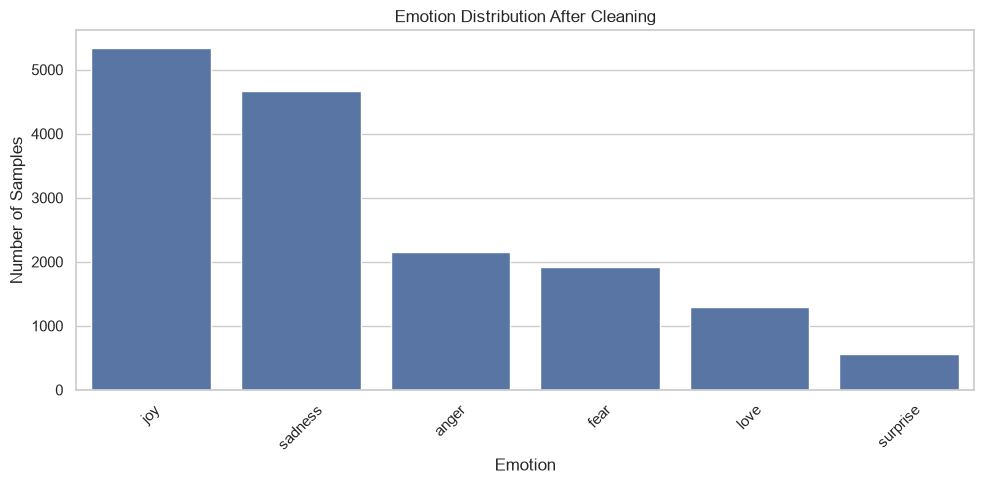

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

emotion_counts = df_clean["emotion"].value_counts()

print("Emotion distribution:")
print(emotion_counts)

print("\nEmotion percentages:")
print((emotion_counts / len(df_clean) * 100).round(2))

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df_clean,
    x="emotion",
    order=emotion_counts.index
)

plt.title("Emotion Distribution After Cleaning")
plt.xlabel("Emotion")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
print("Dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate sentence-label pairs:")
print(df_clean.duplicated(
    subset=["text_original", "emotion"]
).sum())

print("\nUnique emotions:")
print(df_clean["emotion"].unique())

Dataset shape: (15939, 5)

Missing values:
text             0
emotion          0
word_count       0
text_original    0
text_clean       0
dtype: int64

Duplicate sentence-label pairs:
0

Unique emotions:
<ArrowStringArray>
['sadness', 'anger', 'love', 'surprise', 'fear', 'joy']
Length: 6, dtype: str


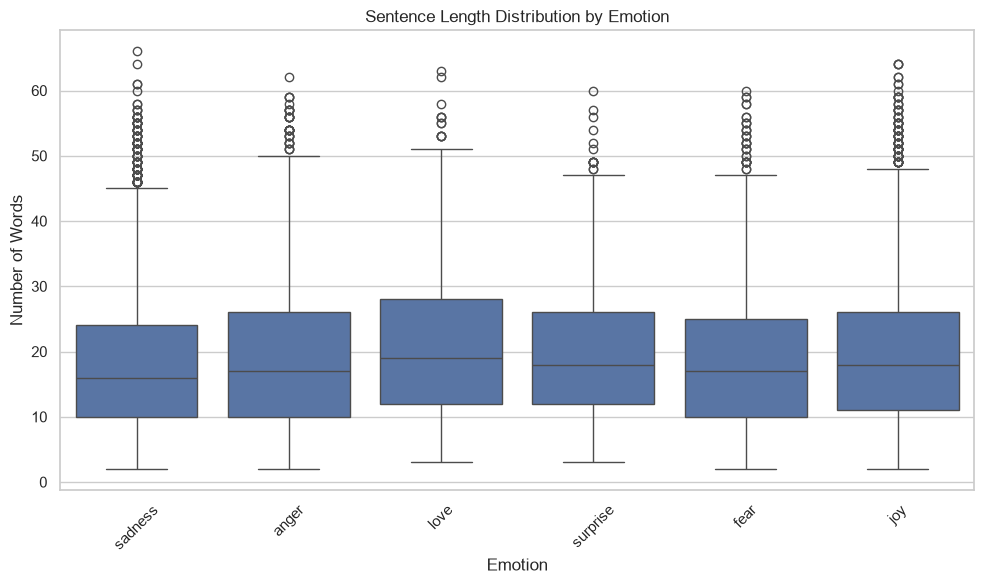

In [16]:
df_clean["word_count"] = (
    df_clean["text_original"].str.split().str.len()
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x="emotion",
    y="word_count"
)

plt.title("Sentence Length Distribution by Emotion")
plt.xlabel("Emotion")
plt.ylabel("Number of Words")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
length_stats = df_clean.groupby("emotion")["word_count"].agg(
    ["mean", "median", "min", "max"]
)

print(length_stats.round(2))

           mean  median  min  max
emotion                          
anger     19.23    17.0    2   62
fear      18.87    17.0    2   60
joy       19.51    18.0    2   64
love      20.74    19.0    3   63
sadness   18.36    16.0    2   66
surprise  20.07    18.0    3   60


In [19]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from collections import Counter
import re

stop_words = set(ENGLISH_STOP_WORDS)

def get_frequent_words(texts):
    words = []

    for sentence in texts:
        tokens = re.findall(r"\b[a-z]+\b", sentence.lower())

        words.extend([
            word for word in tokens
            if word not in stop_words
        ])

    return Counter(words).most_common(15)


for emotion in sorted(df_clean["emotion"].unique()):
    emotion_texts = df_clean[
        df_clean["emotion"] == emotion
    ]["text_original"]

    print(f"\nTop words for {emotion}:")
    print(get_frequent_words(emotion_texts))


Top words for anger:
[('feel', 1455), ('feeling', 718), ('like', 383), ('im', 341), ('just', 220), ('t', 143), ('really', 124), ('time', 118), ('know', 115), ('little', 105), ('people', 105), ('want', 98), ('angry', 85), ('way', 85), ('think', 81)]

Top words for fear:
[('feel', 1204), ('feeling', 740), ('im', 319), ('like', 257), ('just', 172), ('little', 149), ('t', 123), ('know', 117), ('bit', 116), ('really', 99), ('people', 87), ('want', 85), ('time', 83), ('think', 75), ('strange', 75)]

Top words for joy:
[('feel', 3911), ('feeling', 1539), ('like', 1003), ('im', 798), ('just', 421), ('really', 309), ('time', 290), ('t', 258), ('know', 240), ('make', 225), ('want', 203), ('people', 203), ('think', 197), ('good', 196), ('love', 191)]

Top words for love:
[('feel', 914), ('feeling', 378), ('like', 303), ('im', 192), ('love', 97), ('just', 95), ('really', 92), ('know', 79), ('t', 74), ('loving', 68), ('time', 68), ('want', 65), ('sweet', 63), ('caring', 62), ('passionate', 60)]

T

In [20]:
import os

os.makedirs("../data/processed", exist_ok=True)

df_clean.to_csv(
    "../data/processed/cleaned_emotions.csv",
    index=False
)

print("Dataset exported successfully!")
print("Final shape:", df_clean.shape)

Dataset exported successfully!
Final shape: (15939, 5)
